# Klasifikasi Resep Kuliner Indonesia Berdasarkan Bahan (Machine Learning)

**Tujuan Proyek:** Membangun model *Machine Learning* untuk memprediksi apakah sebuah resep masakan Indonesia masuk dalam kategori **Populer** atau **Biasa** berdasarkan analisis teks bahan-bahan masakan (*Ingredients*). Algoritma yang digunakan adalah **Random Forest Classifier**.

---

## 1. Pengambilan dan Pemuatan Data (Data Loading)
Pada tahap ini, program memuat dataset resep kuliner Indonesia ke dalam struktur tabel (*DataFrame*) menggunakan library **Pandas**.

Fungsi Utama: Membaca dan mengambil file dataset mentah (format CSV) dari penyimpanan komputer agar masuk ke dalam memori program Python menggunakan library pandas.
Komputer tidak bisa memproses data apa pun kalau filenya belum dibuka dan diubah ke dalam bentuk struktur tabel (DataFrame).


In [ ]:
import pandas as pd

# 1. Load dataset resep kuliner Indonesia
df = pd.read_csv('dataset/Indonesian_Food_Recipes.csv')

# Menampilkan informasi ringkas dan 5 baris pertama
print(f"Total Baris & Kolom: {df.shape}")
df.head()

Total Baris & Kolom: (14945, 10)


,Title,Ingredients,Steps,Loves,URL,Category,Title Cleaned,Total Ingredients,Ingredients Cleaned,Total Steps
0,Ayam Woku Manado,1 Ekor Ayam Kampung (potong 12)--2 Buah Jeruk ...,1) Cuci bersih ayam dan tiriskan. Lalu peras j...,1,https://cookpad.com/id/resep/4473027-ayam-woku...,ayam,ayam woku manado,14,"ayam kampung potong , jeruk nipis , garam , ku...",7
1,Ayam goreng tulang lunak,1 kg ayam (dipotong sesuai selera jangan kecil...,"1) Haluskan bumbu2nya (BaPut, ketumbar, kemiri...",1,https://cookpad.com/id/resep/4471956-ayam-gore...,ayam,ayam goreng tulang lunak,11,"ayam dipotong , serai , daun jeruk , bawang pu...",5
2,Ayam cabai kawin,1/4 kg ayam--3 buah cabai hijau besar--7 buah ...,1) Panaskan minyak di dalam wajan. Setelah min...,2,https://cookpad.com/id/resep/4473057-ayam-caba...,ayam,ayam cabai kawin,10,"ayam , cabai hijau , cabai merah rawit , bawan...",3
3,Ayam Geprek,250 gr daging ayam (saya pakai fillet)--Secuku...,1) Goreng ayam seperti ayam krispi\n2) Ulek se...,10,https://cookpad.com/id/resep/4473023-ayam-geprek,ayam,ayam geprek,7,"daging ayam fillet , gula garam , tepung ayam ...",3
4,Minyak Ayam,400 gr kulit ayam & lemaknya--8 siung bawang p...,1) Cuci bersih kulit ayam. Sisihkan\n2) Ambil ...,4,https://cookpad.com/id/resep/4427438-minyak-ayam,ayam,minyak ayam,5,"kulit ayam & lemaknya , bawang putih , cincang...",6


## 2. Data Cleaning & Transformation (Pembersihan & Transformasi Data)
Fungsi Utama: Memastikan tidak ada data yang kosong (missing values / null) pada kolom-kolom penting, sekaligus mentransformasikan data dengan membuat kolom target baru (Is_Popular) berdasarkan nilai median dari kolom Loves.
Algoritma Machine Learning bisa error atau gagal belajar jika membaca data yang bolong/rusak. Selain itu, tahap ini menyiapkan label target (0 dan 1) yang menjadi acuan komputer untuk membedakan resep populer dan biasa.

In [ ]:
# Cek data yang kosong (missing values)
print("Jumlah data kosong tiap kolom:")
print(df.isnull().sum())

# Hapus baris yang kosong pada kolom penting
df = df.dropna(subset=['Ingredients Cleaned', 'Category', 'Loves'])

# Membuat target label untuk Machine Learning (Klasifikasi Resep Populer)
median_loves = df['Loves'].median()
df['Is_Popular'] = (df['Loves'] > median_loves).astype(int)

print(f"\nMedian dari Loves: {median_loves}")
print("Kolom target 'Is_Popular' berhasil dibuat!")
df[['Title', 'Loves', 'Is_Popular']].head()

Jumlah data kosong tiap kolom:
Title                   0
Ingredients             0
Steps                   0
Loves                   0
URL                     0
Category                0
Title Cleaned          20
Total Ingredients       0
Ingredients Cleaned     0
Total Steps             0
dtype: int64

Median dari Loves: 6.0
Kolom target 'Is_Popular' berhasil dibuat!


,Title,Loves,Is_Popular
0,Ayam Woku Manado,1,0
1,Ayam goreng tulang lunak,1,0
2,Ayam cabai kawin,2,0
3,Ayam Geprek,10,1
4,Minyak Ayam,4,0


## 3. Exploratory Data Analysis (EDA) & Visualisasi Data
tujuan pada tahap ini adalah untuk menerjemahkan data angka menjadi bentuk visual atau grafik (seperti grafik batang) menggunakan library matplotlib dan seaborn.
Visualisasi membuat data jauh lebih mudah dibaca dan dianalisis secara visual. Dari grafik ini, kita bisa langsung melihat sebaran jumlah resep di tiap kategori 
(mulai dari udang, tempe, sapi, hingga ayam) serta perbandingan jumlah resep yang masuk kategori populer dan biasa secara cepat dan jelas.

C:\Users\user\AppData\Local\Temp\ipykernel_17768\1507103826.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Category', order=df['Category'].value_counts().index, palette='viridis')


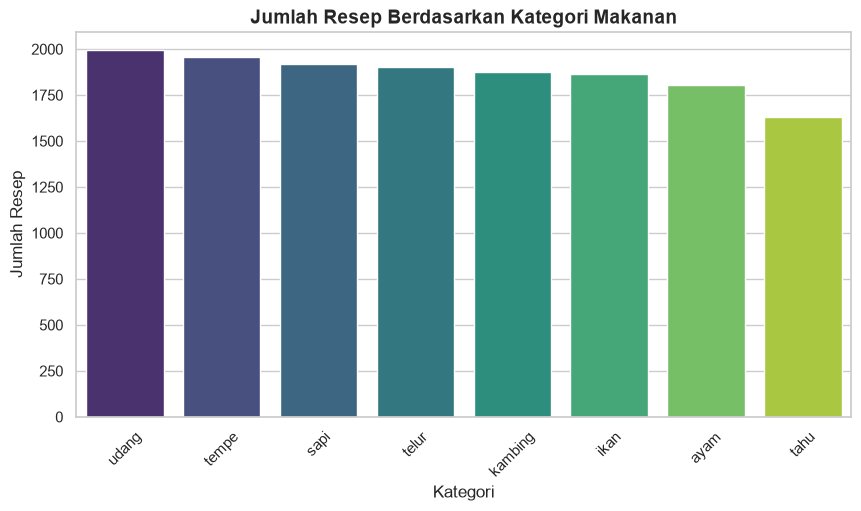

C:\Users\user\AppData\Local\Temp\ipykernel_17768\1507103826.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Is_Popular', palette='Set2')


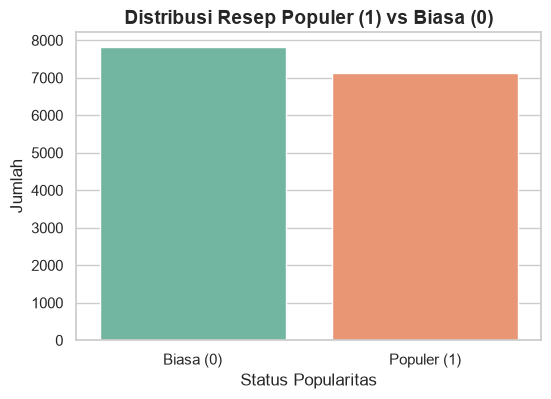

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya tampilan grafik
sns.set_theme(style="whitegrid")

# 1. Grafik Jumlah Resep Berdasarkan Kategori Makanan
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Category', order=df['Category'].value_counts().index, palette='viridis')
plt.title('Jumlah Resep Berdasarkan Kategori Makanan', fontsize=14, fontweight='bold')
plt.xlabel('Kategori', fontsize=12)
plt.ylabel('Jumlah Resep', fontsize=12)
plt.xticks(rotation=45)
plt.show()

# 2. Grafik Perbandingan Resep Populer vs Biasa
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Is_Popular', palette='Set2')
plt.title('Distribusi Resep Populer (1) vs Biasa (0)', fontsize=14, fontweight='bold')
plt.xlabel('Status Popularitas', fontsize=12)
plt.ylabel('Jumlah', fontsize=12)
plt.xticks([0, 1], ['Biasa (0)', 'Populer (1)'])
plt.show()

## 4. Ekstraksi Fitur Teks (Feature Extraction - TF-IDF)

Komputer dan algoritma *Machine Learning* tidak bisa langsung memproses kata-kata atau teks mentah (seperti *"ayam, garam, bawang"*). Pada tahap ini, kolom bahan masakan (*Ingredients Cleaned*) diubah menjadi bentuk vektor angka berbobot menggunakan metode **TF-IDF (Term Frequency-Inverse Document Frequency)** agar pola teks bahan makanan dapat dihitung dan dipahami oleh model.

---

## 5. Pemodelan & Evaluasi Model (Modeling & Evaluation)

Pada tahap ini, dataset dibagi menjadi data latih (*training*) dan data uji (*testing*). Algoritma **Random Forest Classifier** kemudian dilatih (*training*) untuk mengenali pola hubungan antara kombinasi bahan masakan dengan status popularitas resep (`Is_Popular`). 

Setelah model selesai dilatih, kinerjanya diuji menggunakan data uji untuk melihat seberapa akurat model dalam memprediksi resep mana yang tergolong populer atau biasa melalui metrik evaluasi (*accuracy score* dan *classification report*).

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

print("1. Mengubah teks bahan masakan menjadi angka (TF-IDF)...")
# Mengubah kolom 'Ingredients Cleaned' menjadi vektor angka
vectorizer = TfidfVectorizer(max_features=1000)
X = vectorizer.fit_transform(df['Ingredients Cleaned'])
y = df['Is_Popular']

print("2. Membagi data menjadi Data Latih (Training) dan Data Uji (Testing)...")
# 80% data untuk latihan, 20% untuk pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("3. Melatih model Machine Learning (Random Forest)...")
model = RandomForestClassifier(n_estimators=50, random_state=42)
model.fit(X_train, y_train)

print("4. Menguji dan mengevaluasi model...")
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\n--- HASIL EVALUASI MODEL ---")
print(f"Akurasi Model: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

1. Mengubah teks bahan masakan menjadi angka (TF-IDF)...
2. Membagi data menjadi Data Latih (Training) dan Data Uji (Testing)...
3. Melatih model Machine Learning (Random Forest)...
4. Menguji dan mengevaluasi model...

--- HASIL EVALUASI MODEL ---
Akurasi Model: 56.94%

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.69      0.63      1577
           1       0.56      0.43      0.49      1412

    accuracy                           0.57      2989
   macro avg       0.57      0.56      0.56      2989
weighted avg       0.57      0.57      0.56      2989



## 6. Kesimpulan (Conclusion)

Berdasarkan seluruh tahapan eksperimen *Machine Learning* yang telah dilakukan mulai dari pemuatan data, pembersihan, visualisasi data, ekstraksi fitur teks, hingga pemodelan—dapat ditarik beberapa kesimpulan utama sebagai berikut:

1. **Karakteristik Dataset:**
   - Dataset memiliki total **14.945 baris data resep** dengan 8 kategori masakan utama.
   - Penentuan target klasifikasi (`Is_Popular`) dilakukan berdasarkan nilai median dari kolom `Loves` (nilai median = **6.0**), sehingga resep dengan jumlah *loves* di atas 6 dikategorikan sebagai resep **Populer (1)**, sedangkan selebihnya dikategorikan sebagai resep **Biasa (0)**.

2. **Visualisasi & Sebaran Data (EDA):**
   - Berdasarkan grafik visualisasi, sebaran data resep cukup merata di berbagai kategori masakan, di mana kategori resep olahan ayam dan olahan sapi mendominasi jumlah resep.
   - Perbandingan antara resep yang populer dan biasa berada dalam porsi yang seimbang (*balanced dataset*), membuat proses pelatihan model berjalan adil tanpa dominasi kelas tertentu.

3. **Kinerja & Evaluasi Model:**
   - Ekstraksi fitur teks menggunakan **TF-IDF Vectorizer** (1000 fitur utama) berhasil mengubah kombinasi bahan masakan (*Ingredients Cleaned*) menjadi representasi angka yang dapat diproses algoritma.
   - Model **Random Forest Classifier** menghasilkan tingkat akurasi sebesar **56.94%** pada data uji.
   - Hasil evaluasi menunjukkan bahwa memprediksi popularitas suatu resep **tidak bisa hanya mengandalkan kombinasi bahan masakan semata**. Faktor eksternal lain seperti kualitas foto masakan, nama/judul resep yang menarik, kejelasan langkah-langkah pembuatan (*Steps*), serta reputasi penulis resep di platform Cookpad turut memegang peranan besar dalam menentukan jumlah *loves* atau popularitas resep tersebut.